In [1]:
import skfuzzy as fuzz
print("scikit-fuzzy installed and imported successfully!")
import numpy as np
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl

scikit-fuzzy installed and imported successfully!


# Selección de áreas para el establecimiento de Pinus patula
## Entradas
*  Temperatura(temp) (°C): -14 - 40 (fria, intermedia, calida)
*  Precipitación(prec) (mm): 600-2,500 (poca, media, abundante)
*  Altura(alt) (msnm): 1,500-3,100 (baja, media, alta)
## Salida
* indice_aptitud_ambiental(%): 0-100(ligeramente_optima, medianamente_optima, optima)

In [39]:
#Variables difusas de entrada
temp = ctrl.Antecedent(np.arange(-14, 41,0.1),'Temperatura')
prec = ctrl.Antecedent(np.arange(600, 2500,1),'Precipitacion')
alt = ctrl.Antecedent(np.arange(1500, 3101,1),'Altura')

#Variables difusas de salida
indice = ctrl.Consequent(np.arange(0, 101,1),'indice_de_aptitud')

In [ ]:
#Funciones de membresia
# trapmf es por trapecio, tri por triangulo

#Temperatura
temp['fria'] = fuzz.trimf(temp.universe,[-14,-14,10])
temp['intermedia'] = fuzz.trapmf(temp.universe,[8,10,20,32])
temp['calida'] = fuzz.trimf(temp.universe,[30,40,40])

# Precipitacion
prec['poca'] = fuzz.trapmf(prec.universe,[600,600,1000,1250])
prec['media'] = fuzz.trimf(prec.universe,[1100,1200,1600])
prec['abundante'] = fuzz.trapmf(prec.universe,[1400,1500,2500,2650])

#Altura
alt['baja'] = fuzz.trapmf(alt.universe,[1400,1500,1600,1750])
alt['media'] = fuzz.trapmf(alt.universe,[1600,1800,2400,2750])
alt['alta'] = fuzz.trimf(alt.universe,[2600,3100,3100])



c:\Users\diana\anaconda3\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


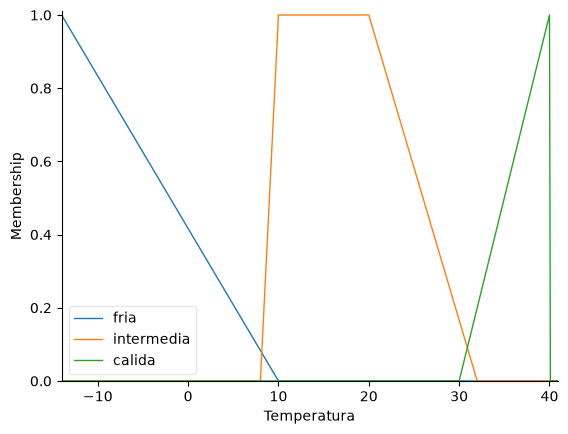

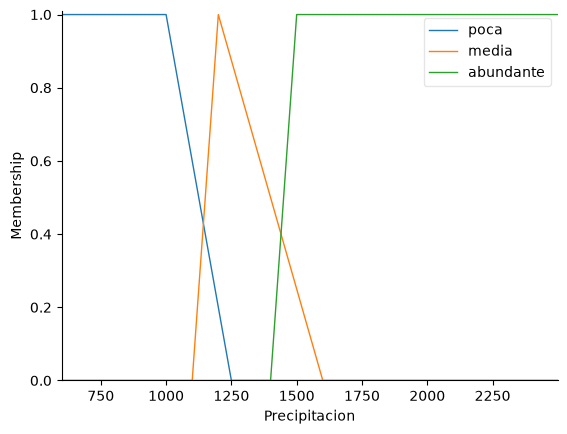

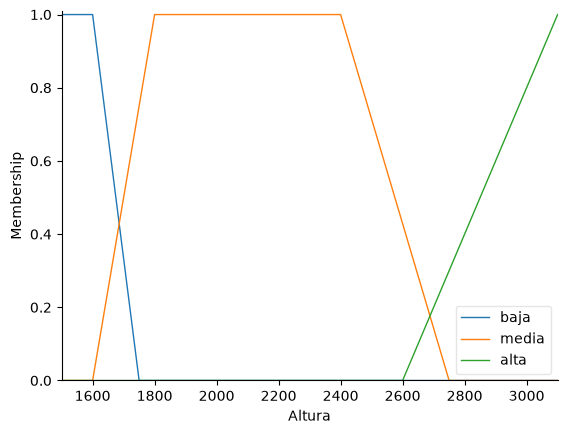

In [42]:
#Graficar funciones de entrada
%matplotlib inline
temp.view()
prec.view()
alt.view()
plt.show()

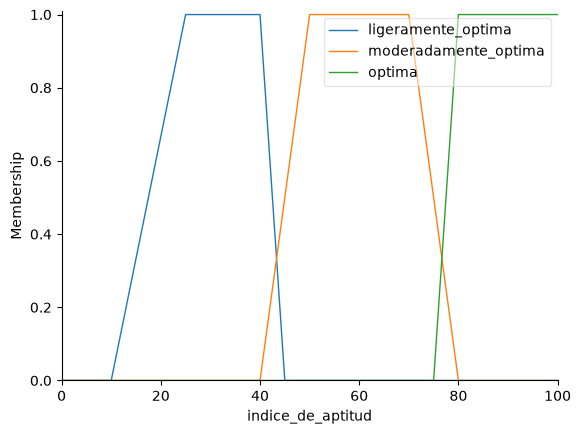

In [ ]:
#Funcion de pertenencia de la salida

indice['ligeramente_optima'] = fuzz.trapmf(indice.universe,[10,25,40,45])
indice['moderadamente_optima'] = fuzz.trapmf(indice.universe,[40,50,70,80])
indice['optima'] = fuzz.trapmf(indice.universe,[75,80,100,100])
indice.view()
plt.show()

In [ ]:

# Reglas del sistema difuso

reglas_indice = [
    # Temperatura fria
    ctrl.Rule(temp['fria'] & prec['poca'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['fria'] & prec['poca'] & alt['media'],indice['ligeramente_optima']),
    ctrl.Rule(temp['fria'] & prec['poca'] & alt['alta'],indice['ligeramente_optima']),

    ctrl.Rule(temp['fria'] & prec['media'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['fria'] & prec['media'] & alt['media'],indice['moderadamente_optima']),
    ctrl.Rule(temp['fria'] & prec['media'] & alt['alta'],indice['moderadamente_optima']),

    ctrl.Rule(temp['fria'] & prec['abundante'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['fria'] & prec['abundante'] & alt['media'],indice['moderadamente_optima']),
    ctrl.Rule(temp['fria'] & prec['abundante'] & alt['alta'],indice['moderadamente_optima']),

    # Temperatura Intermedia
    ctrl.Rule(temp['intermedia'] & prec['poca'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['intermedia'] & prec['poca'] & alt['media'],indice['ligeramente_optima']),
    ctrl.Rule(temp['intermedia'] & prec['poca'] & alt['alta'],indice['ligeramente_optima']),

    ctrl.Rule(temp['intermedia'] & prec['media'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['intermedia'] & prec['media'] & alt['media'],indice['optima']),
    ctrl.Rule(temp['intermedia'] & prec['media'] & alt['alta'],indice['optima']),

    ctrl.Rule(temp['intermedia'] & prec['abundante'] & alt['baja'],indice['moderadamente_optima']),
    ctrl.Rule(temp['intermedia'] & prec['abundante'] & alt['media'],indice['moderadamente_optima']),
    ctrl.Rule(temp['intermedia'] & prec['abundante'] & alt['alta'],indice['ligeramente_optima']),

    # Temperatura calida 
    ctrl.Rule(temp['calida'] & prec['poca'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['calida'] & prec['poca'] & alt['media'],indice['ligeramente_optima']),
    ctrl.Rule(temp['calida'] & prec['poca'] & alt['alta'],indice['ligeramente_optima']),

    ctrl.Rule(temp['calida'] & prec['media'] & alt['baja'],indice['ligeramente_optima']),
    ctrl.Rule(temp['calida'] & prec['media'] & alt['media'],indice['moderadamente_optima']),
    ctrl.Rule(temp['calida'] & prec['media'] & alt['alta'],indice['moderadamente_optima']),

    ctrl.Rule(temp['calida'] & prec['abundante'] & alt['baja'],indice['moderadamente_optima']),
    ctrl.Rule(temp['calida'] & prec['abundante'] & alt['media'],indice['moderadamente_optima']),
    ctrl.Rule(temp['calida'] & prec['abundante'] & alt['alta'],indice['ligeramente_optima'])
    
    ]


# Crear  el sistema y el simulador
sistema_indice = ctrl.ControlSystem(reglas_indice)
simulador_indice = ctrl.ControlSystemSimulation(sistema_indice)

print("Número de reglas:", len(reglas_indice))


Número de reglas: 27


In [45]:
#Controlador
sistema_indice = ctrl.ControlSystem(reglas_indice)
simulador_indice = ctrl.ControlSystemSimulation(sistema_indice)

In [54]:
#Declaramos una funcion para la implementacion
def indice_adaptacion(Temperatura, Precipitacion, Altura, mostrar=True):
  t = float(np.clip(Temperatura,-14,40))
  p = float(np.clip(Precipitacion,600,2500))
  a = float(np.clip(Altura,1400,3100))

  simulador_indice.input['Temperatura'] = t
  simulador_indice.input['Precipitacion'] = p
  simulador_indice.input['Altura'] = a

  simulador_indice.compute()
  salida = simulador_indice.output['indice_de_aptitud']

  if mostrar:
    print('Temperatura', t)
    print('Precipitacion',p)
    print('Altura',a)
    print(f'Índice de aptitud ambiental: {salida:.2f}')
    
  return salida

Temperatura 12.0
Precipitacion 1300.0
Altura 2000.0
Índice de aptitud ambiental: 88.41


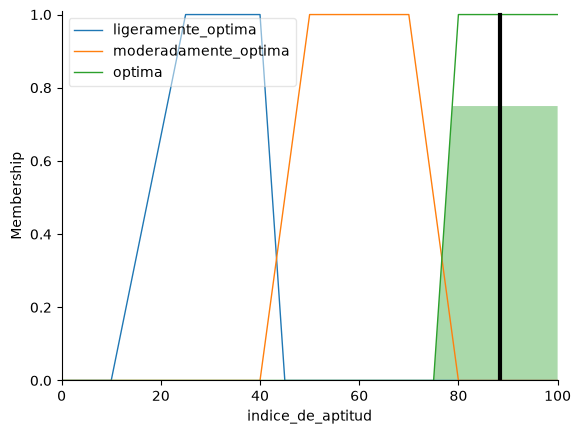

In [58]:
# Correr primer ejemplo
porcentaje_de_aptitud = indice_adaptacion(12,1300,2000)
indice.view(sim=simulador_indice)
plt.show()